<a href="https://colab.research.google.com/github/MhiyaJ/My-GIS-Stuff/blob/main/CCHSDistrict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTING PROGRAMS

Source: theaok.github.io/gisPy/, map.ipynb, Retrieved October 20, 2026

In [256]:
%%capture

import os, zipfile
import pandas as pd #
import matplotlib.pyplot as plt

import geopandas as gpd

import mapclassify

import seaborn as sns

from matplotlib.patches import Ellipse

from matplotlib.patheffects import withStroke

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files

from geopandas.tools import geocode

from google.colab.data_table import DataTable
DataTable.max_columns = 250

gpd.__version__

In [257]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Secondary_-5568767075062576326.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njrhs = gpd.read_file('School_Districts_Secondary.shp')

njhighschools.zip		    School_Districts_Secondary.shx
sample_data			    School_Districts_Unified.cpg
School_Districts_Secondary.cpg	    School_Districts_Unified.dbf
School_Districts_Secondary.dbf	    School_Districts_Unified.prj
School_Districts_Secondary.prj	    School_Districts_Unified.shp
School_Districts_Secondary.shp	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp.xml  School_Districts_Unified.shx


In [258]:
! wget -q -O njhighschools.zip https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/School_Districts___Unified_7341673536716239500.zip

zip_ref=zipfile.ZipFile ('njhighschools.zip', 'r'); zip_ref.extractall(); zip_ref.close()
!ls

njsch = gpd.read_file('School_Districts_Unified.shp')

njhighschools.zip		    School_Districts_Secondary.shx
sample_data			    School_Districts_Unified.cpg
School_Districts_Secondary.cpg	    School_Districts_Unified.dbf
School_Districts_Secondary.dbf	    School_Districts_Unified.prj
School_Districts_Secondary.prj	    School_Districts_Unified.shp
School_Districts_Secondary.shp	    School_Districts_Unified.shp.xml
School_Districts_Secondary.shp.xml  School_Districts_Unified.shx


In [259]:
njrhs.columns
njsch.columns

Index(['NJDOE_ID_S', 'DIST_NAME', 'SCSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

Index(['NJDOE_ID_U', 'DIST_NAME', 'UNSDLEA', 'SD_TYPE', 'GEOID', 'geometry'], dtype='object')

In [260]:
njrhs.head(5)

,NJDOE_ID_S,DIST_NAME,SCSDLEA,SD_TYPE,GEOID,geometry
0,03-4300,Ramapo Indian Hills Regional High School District,13560,S,3413560,"POLYGON ((581460.48 800555.65, 581472.241 8005..."
1,19-3660,North Hunterdon-Voorhees Regional High School ...,11610,S,3411610,"POLYGON ((391770.815 705704.676, 392388.938 70..."
2,31-3980,Passaic County Manchester Regional High School...,12600,S,3412600,"POLYGON ((584057.82 765144.57, 584036.38 76509..."
3,05-2610,Lenape Regional High School District,08490,S,3408490,"POLYGON ((389198.15 423712.25, 389455.47 42371..."
4,25-4365,Red Bank Regional School District,13750,S,3413750,"POLYGON ((616941.34 555139.98, 617060.857 5549..."


In [261]:
#Googled - Splitting columns into 2, Option 3: Split text and numbers using Regular Expressions
njrhs["NJDOE_ID_S"] = njrhs["NJDOE_ID_S"].astype(str)
njrhs[["CountyCode", "DistrictCode"]] = njrhs["NJDOE_ID_S"].str.extract(r"(\d{2}).*(\d{4})")

njsch["NJDOE_ID_U"] = njsch["NJDOE_ID_U"].astype(str)
njsch[["CountyCode", "DistrictCode"]] = njsch["NJDOE_ID_U"].str.extract(r"(\d{2}).*(\d{4})")

In [262]:
#new columns, DistrictCode and CountyCode, with County Code only including Camden County
njrhs2 = njrhs[njrhs['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID', 'geometry']]
njrhs2['DistrictCode']=njrhs2.DistrictCode.str.strip()

njsch2=njsch[njsch['CountyCode'] == '07'][['DistrictCode', 'CountyCode', 'DIST_NAME', 'GEOID','geometry']]
njsch2['DistrictCode']=njsch2.DistrictCode.str.strip()

In [263]:
#Googled: How to combine onto 1 spreadsheet
#Add optional column to keep track where rows come from
njsch2['type']='Unified'
njrhs2['type']='Secondary'

#Stack them into one single geodataframe
cchs=pd.concat([njsch2, njrhs2], ignore_index=True)

#convert back to geodataframe to preserve map plotting capabilities
cchs=gpd.GeoDataFrame(cchs,geometry='geometry')

cchs

,DistrictCode,CountyCode,DIST_NAME,GEOID,geometry,type
0,5820,07,Winslow Township School District,3418060,"POLYGON ((368609.977 344389.586, 368631.27 344...",Unified
1,0150,07,Audubon Public School District,3401050,"POLYGON ((333599.519 389532.256, 334908.018 38...",Unified
2,0940,07,Collingswood Public School District,3403420,"POLYGON ((329936.77 398206.61, 330020.49 39819...",Unified
3,1880,07,Haddon Heights School District,3406330,"POLYGON ((338431.442 383843.61, 338435.82 3836...",Unified
4,2130,07,Hi Nella,3407080,"POLYGON ((346458.121 367972.644, 346568.817 36...",Unified
5,3770,07,Oaklyn Public School District,3411940,"POLYGON ((331980.807 391389.812, 331778.88 391...",Unified
6,0800,07,Cherry Hill School District,3403000,"POLYGON ((347458.19 406942.14, 347464.79 40692...",Unified
7,1900,07,Haddonfield School District,3406390,"POLYGON ((341402.77 394798.54, 341480.9 394783...",Unified
8,4110,07,Pine Hill School District,3412990,"POLYGON ((351592.589 354425.759, 351577.79 351...",Unified
9,1890,07,Haddon Township School District,3406360,"MULTIPOLYGON (((325315.69 389559.475, 325405.0...",Unified


In [283]:
%%capture
!pip install adjustText

In [284]:
from adjustText import adjust_text

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

([Text(370072.7066306503, 315658.1276386258, 'Winslow Township'),
  Text(336999.4246665804, 384598.4213318606, 'Audubon'),
  Text(342335.48357809125, 396487.7347666257, 'Collingswood'),
  Text(344424.9726544193, 380577.0366691216, 'Haddon Heights'),
  Text(340306.2623842831, 366414.0658491504, 'Hi Nella'),
  Text(324605.4170354046, 391121.088263341, 'Oaklyn'),
  Text(363081.11794369575, 390721.2440918298, 'Cherry Hill'),
  Text(350420.84395170974, 387866.27718965, 'Haddonfield'),
  Text(361831.2114665349, 347155.53917157836, 'Pine Hill'),
  Text(343615.1124740578, 392946.39165926585, 'Haddon Township'),
  Text(362219.6204785061, 357720.75101462344, 'Lindenwold'),
  Text(359448.3586631292, 376212.81011298264, 'Lawnside School Distric'),
  Text(415289.0194739782, 332137.8608400872, 'Waterford Township'),
  Text(330901.3379286666, 376643.05585209915, 'Barrington'),
  Text(325690.1397006253, 397949.7702161956, 'Woodlynne'),
  Text(340715.6329702324, 359422.4308974651, 'Laurel Springs'),
  

[]

[]

(np.float64(308456.66427294584),
 np.float64(430201.67503440706),
 np.float64(276823.57176200213),
 np.float64(429700.2905748793))

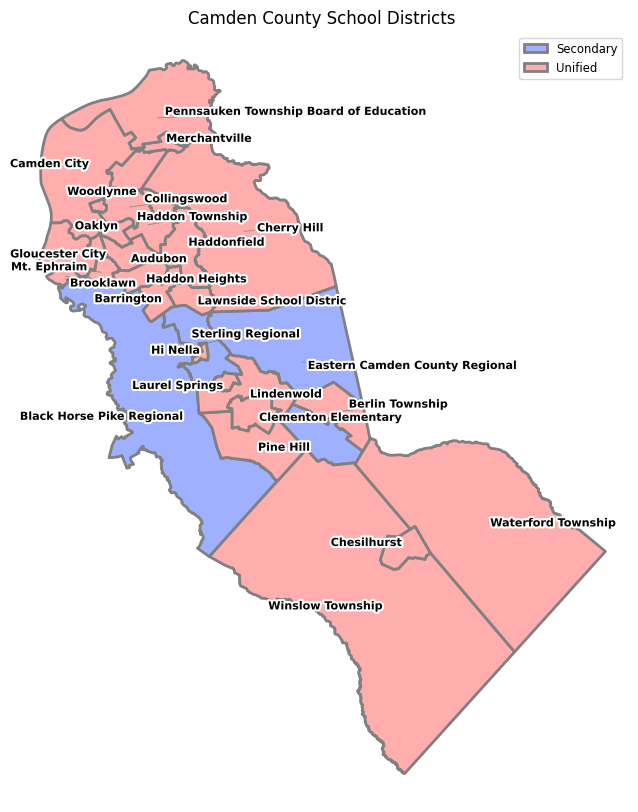

In [307]:
fig, ax = plt.subplots(1, figsize=(10,10))
cchs.plot(ax=ax,column='type',legend=True,cmap='berlin',
         edgecolor='grey',linewidth=2,legend_kwds={
        'loc':'upper right','title_fontsize':'medium','fontsize':'small','markerscale':1.4})

# Prompted Gemini to fix label overlap
texts = []
for x, y, label in zip(cchs.geometry.centroid.x, cchs.geometry.centroid.y, cchs.DIST_NAME):
       #Keep label names brief by stripping common suffixes to reduce overlap further
    display_label = label.replace(" Public School District", "").replace(" School District", "").replace(" Board Of Education", "")
    t = ax.text(x, y, display_label, fontsize=8, color='black', fontweight='bold',
                horizontalalignment='center', verticalalignment='center')
    t.set_path_effects([withStroke(linewidth=3, foreground='white')])
    texts.append(t)

# Automatically resolve all overlaps
adjust_text(texts, arrowprops=dict(arrowstyle="-", color='gray', lw=0.5))

ax.title.set_text("Camden County School Districts")
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.04)
ax.axis("off")
plt.show()

In [287]:
PrgXls = pd.read_excel('https://github.com/MhiyaJ/My-GIS-Stuff/raw/refs/heads/main/After%20School%20Programs.2.xlsx')

In [288]:
PrgXls.head()

,After School Programs,Address,Unnamed: 2
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health


In [289]:
#Rename columns and separated program types
PrgXls = PrgXls.rename(columns={'Unnamed: 2': 'Prog Type'})
PrgXls

,After School Programs,Address,Prog Type
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health
3,Mark Newbie Elementary School,"2 E. Browning Rd., Collingswood, NJ 08108",Health
4,Zane North Elementary School,"801 Stokes Ave., Collingswood, NJ 08108",Health
5,Collingswood Early Childhood Center,"201 Dayton Ave., Collingswood, NJ 08108",Health
6,Parkview Preschool,"700 W. Browning Rd., Collingswood, NJ 08107",Health
7,Oaklyn Public School,"136 Kendall Blvd., Oaklyn, NJ 08107",Health
8,"After-School All-Stars, Copewood Campus","1650 Copewood St., Camden, NJ 08103",General
9,"After-School All-Stars, Mt. Ephraim Campus","1575 Mt. Ephraim Ave., Camden, NJ 08104",General


In [290]:
#Prompted Gemini to fix error due to length of after school program list

# Combine 'Address' and 'City' into a single string for better geocoding accuracy
full_addresses = PrgXls['Address'].astype(str) + ", New Jersey"

# Geocode using 'arcgis' provider to avoid Nominatim's strict 429 rate limiting
geo = geocode(full_addresses, provider='arcgis', timeout=10)
geo.head(3)

,geometry,address
0,POINT (-75.06635 39.9196),"265 Lincoln Ave, Collingswood, New Jersey, 08108"
1,POINT (-75.08938 39.91174),"400 Comly Ave, Oaklyn, New Jersey, 08107"
2,POINT (-75.07578 39.91817),"480 Haddon Ave, Collingswood, New Jersey, 08108"


In [291]:
#PrgXls=gpd.GeoDataFrame(cchs,geometry='geometry'), didn't run therefore prompted Gemini to explain and fix error
# Assign the geocoded geometry to the main DataFrame
PrgXls['geometry'] = geo['geometry']

# Convert to a GeoDataFrame using the new geometry column
PrgXls = gpd.GeoDataFrame(PrgXls, geometry='geometry')

# End of Gemini assistance

#Strip to categorize
PrgFsc = PrgXls[PrgXls['Prog Type'].str.strip() == 'Family Success Center']
PrgCom = PrgXls[PrgXls['Prog Type'].str.strip() == 'Community Center']
PrgGen = PrgXls[PrgXls['Prog Type'].str.strip() == 'General']
PrgHea = PrgXls[PrgXls['Prog Type'].str.strip() == 'Health']

PrgXls.head(3)

,After School Programs,Address,Prog Type,geometry
0,William P Tatem Elementary,"265 Lincoln Ave, Collingswood, NJ 08108",Health,POINT (-75.06635 39.9196)
1,Thomas Sharp Elementary,"400 Comly Ave., Collingswood, NJ 08108",Health,POINT (-75.08938 39.91174)
2,James A Garfield Elementary School,"480 Haddon Ave., Collingswood, NJ 08108",Health,POINT (-75.07578 39.91817)


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

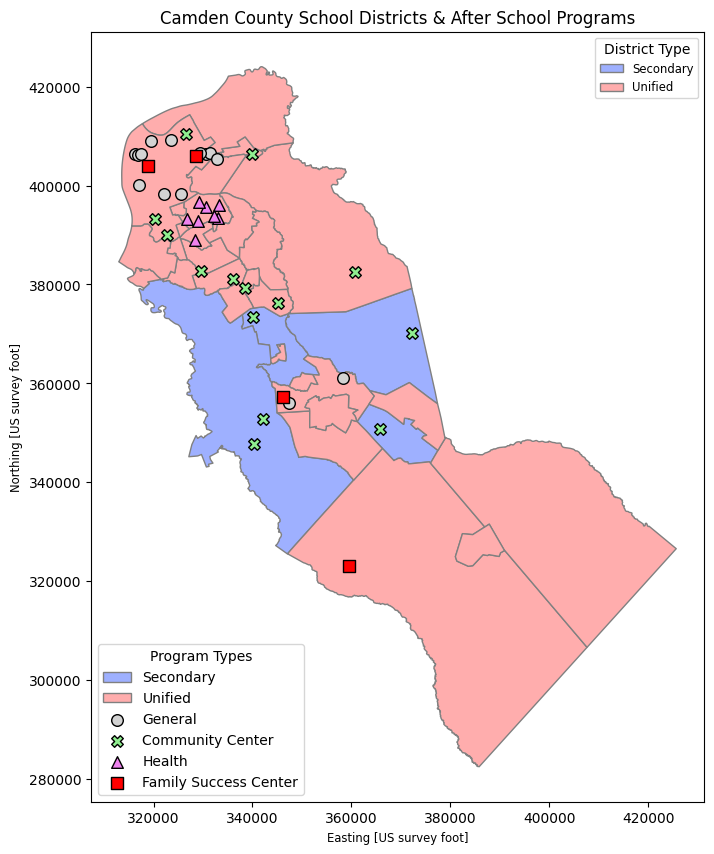

In [310]:
# Original run
fig, ax = plt.subplots(1, figsize=(10,10))

cchs.plot(ax=ax, column='type', legend=True, cmap='berlin',
          edgecolor='grey', linewidth=1, legend_kwds={
          'loc':'upper right', 'title_fontsize':'medium', 'fontsize':'small', 'markerscale':1.4,'title':'District Type'})

# Prompted Gemini to create two legends
# Save the first legend (District Type) to prevent it from being overwritten
District_legend = ax.get_legend()

PrgGen_proj.plot(ax=ax, marker='o', color='lightgrey', markersize=70, label='General', edgecolor='black')
PrgCom_proj.plot(ax=ax, marker='X', color='lightgreen', markersize=70, label='Community Center', edgecolor='black')
PrgHea_proj.plot(ax=ax, marker='^', color='violet', markersize=70, label='Health', edgecolor='black')
PrgFsc_proj.plot(ax=ax, marker='s', color='red', markersize=70, label='Family Success Center', edgecolor='black')

# Create the second legend (for Prog Type) on the lower left
Program_legend = ax.get_legend()

ax.legend(loc='lower left', title="Program Types")
# End of original run


# Add the first legend back to the axes manually so both are visible
if District_legend is not None:
    ax.add_artist(District_legend)

# End of Gemini prompts

ax.title.set_text("Camden County School Districts & After School Programs")

# Highlight ellipse (e.g. for Collingswood area)
ax = Ellipse(xy=(340000, 3930000), width=0.04, height=0.04, edgecolor='b', fc='None', lw=2.5)

#ax.axis('off')
plt.show()